## Question:
What are the mean and standard deviation of a player's board position after completing exactly 3 turns? 

## Description
1: The random vairible that I will be exploring is the number of spaces the player is expected to move after 3 turns. It could be between 

2: The trial will be simmulating the first 3 turns of the player. I will randomize a number 1-6, each value equals one spot on the board. There is some varribilty with the Chutes and Ladders placed on the map. If a player lands on a ladder they will be boosted up but if they land on a chute they will be taken down.

In [259]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [260]:
jumps = {
    # Ladders
    1: 38,
    4: 14,
    9: 31,
    16: 6,
    21: 42,
    28: 84,
    36: 44,
    51: 67,
    71: 91,
    80: 100,
    # Chutes
    16: 6,
    47: 26,
    49: 11,
    56: 53,
    62: 19,
    64: 60,
    87: 24,
    93: 73,
    95: 75,
    98: 78,
}

In [280]:
def simulate_one_game():
    position = 0

    for turn in range(3):
        roll = np.random.randint(1, 7)
        position += roll
        
        if position in jumps:
            position = jumps[position]

    return position

In [281]:
num_simulations = 500000
final_positions = []

for _ in range(num_simulations):
    end_position = simulate_one_game()
    final_positions.append(end_position)

In [282]:
print(final_positions)

[45, 6, 26, 31, 48, 13, 12, 15, 8, 15, 48, 45, 12, 7, 18, 37, 15, 26, 26, 13, 12, 42, 19, 48, 22, 12, 26, 11, 11, 7, 31, 10, 13, 20, 42, 31, 8, 13, 11, 6, 11, 33, 26, 11, 15, 33, 15, 10, 43, 20, 20, 11, 11, 43, 11, 11, 50, 19, 42, 8, 17, 11, 26, 33, 14, 8, 8, 18, 8, 43, 8, 42, 31, 7, 22, 12, 33, 10, 46, 14, 15, 10, 31, 11, 10, 11, 20, 35, 23, 15, 22, 44, 6, 26, 12, 14, 43, 12, 42, 8, 32, 6, 10, 46, 10, 13, 18, 23, 8, 44, 24, 6, 35, 15, 13, 12, 14, 31, 18, 6, 43, 6, 35, 14, 10, 31, 17, 35, 26, 41, 10, 10, 48, 44, 31, 12, 13, 41, 20, 42, 12, 17, 11, 46, 26, 12, 19, 11, 11, 12, 43, 18, 10, 14, 10, 33, 12, 15, 10, 8, 33, 24, 45, 8, 8, 12, 43, 44, 46, 31, 32, 17, 12, 10, 7, 10, 10, 11, 12, 12, 45, 12, 45, 20, 10, 37, 11, 6, 23, 45, 18, 14, 6, 6, 8, 22, 44, 24, 8, 10, 11, 44, 15, 19, 12, 11, 8, 22, 14, 12, 13, 15, 31, 44, 37, 34, 42, 11, 42, 25, 14, 13, 32, 6, 11, 14, 10, 31, 34, 34, 11, 11, 48, 8, 31, 24, 46, 44, 43, 13, 12, 50, 44, 12, 8, 13, 14, 15, 22, 17, 15, 31, 37, 6, 12, 13, 13, 19, 

In [288]:
df = pd.DataFrame({"FinalPosition": final_positions})

In [289]:
mean_position = df["FinalPosition"].mean()
std_dev_position = df["FinalPosition"].std()

In [290]:
print(
    f"Mean position after 3 turns: {mean_position:.2f}"
) 
print(
    f"Standard deviation after 3 turns: {std_dev_position:.2f}"
)  

Mean position after 3 turns: 21.48
Standard deviation after 3 turns: 13.12


In [291]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

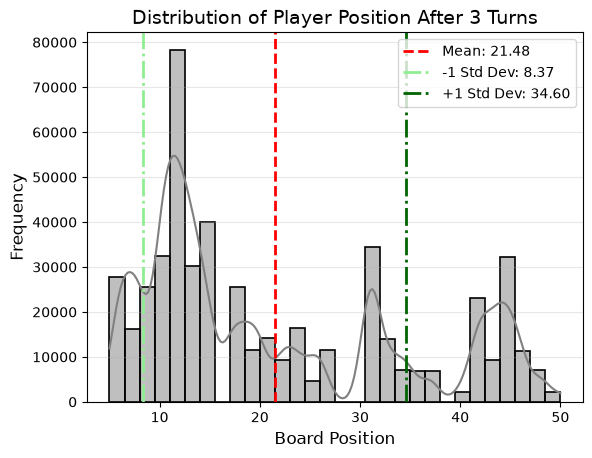

In [298]:
sns.histplot(
    df["FinalPosition"],
    bins=30,  
    color="grey",  
    edgecolor="black",  
    linewidth=1.2, 
    kde=True, 
)

plt.axvline(
    mean_position,
    color="red",
    linestyle="dashed",
    linewidth=2,
    label=f"Mean: {mean_position:.2f}",
)

plt.axvline(
    mean_position - std_dev_position,
    color="lightgreen",
    linestyle="dashdot",
    linewidth=2,
    label=f"-1 Std Dev: {(mean_position - std_dev_position):.2f}",
)
plt.axvline(
    mean_position + std_dev_position,
    color="darkgreen",
    linestyle="dashdot",
    linewidth=2,
    label=f"+1 Std Dev: {(mean_position + std_dev_position):.2f}",
)

plt.title("Distribution of Player Position After 3 Turns", fontsize=14)
plt.xlabel("Board Position", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

## The histogram is left-skewed and peaks at 24–25 turns. The data is very spread out. I think it is intresting where all the peaks are. This tells me where the ladders are becuase that's where a lot of people are ending up.